<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG103 - Visualización de datos en Geología**</span>

Bienvenido al curso!!!

Vamos a revisar ejemplos de <span style="color:gold">visualización de datos</span> en Geología usando código en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python, estadística y geología general.

<span style="color:gold; font-size:20px">**Visualización de datos** </span>

***
- [¿Python para la visualización de datos?](#parte-1)
- [Seaborn](#parte-2)
- [Pyrolite](#parte-3)
- [Mplstereonet](#parte-4)

***

<a id="parte-1"></a>

### <span style="color:lightgreen">**¿Python para la visualización de datos?**
***
La **visualización de datos** consiste en intentar entender los datos a través de un contexto visual de tal manera que podamos detectar patrones, tendencias y correlaciones. <br>
Puedes revisar diferentes estilos de visualización en la página de [DataVizProject](https://datavizproject.com/).

Las principales ventajas de realizar visualizaciones dentro de Python son:

- Acceso a múltiples <span style="color:lightgreen">librerías</span> (e.g. `Matplotlib`, `Seaborn`, `Mplstereonet`, etc.) con diferentes funcionalidades y aplicaciones en diferentes disciplinas.
- <span style="color:lightgreen">Escalabilidad</span> y  <span style="color:lightgreen">automatización</span> con el potencial de generar decenas de gráficos usando solamente unas pocas líneas de código.
- Amplia gama de figuras y estilos de visualización con un alto nivel de <span style="color:lightgreen">personalización</span>, lo que permite la creación de nuevos tipos de figuras.


***

<a id="parte-2"></a>

### <span style="color:lightgreen">**Seaborn**
***
Esta librería posee una interface de alto nivel para la creación de figuras atractivas. Usa menos líneas de código comparado con Matplotlib.

En los siguientes ejemplos, usaremos información geoquímica de **rocas volcánicas** para crear diferentes tipos de gráficos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(context="notebook", style="ticks")

La información se encuentra en un archivo CSV llamado `rocas.csv`. <br>
Esta información ha sido procesada previamente y proviene de una base de datos geoquímica de uso público llamada [GEOROC](http://georoc.mpch-mainz.gwdg.de/georoc/Start.asp). <br>
Abriremos estos archivos a través de la librería `Pandas` y usaremos la función `read_csv`.

> Si al ejecutar `read_csv` ocurren problemas para leer el archivo, puedes probar usando `encoding="ISO-8859-1"` (por defecto se usa `encoding="utf-8"`).

In [ ]:
rocas = pd.read_csv("files/rocas.csv", encoding="ISO-8859-1")

In [ ]:
rocas

Revisaremos la información general del cuadro usando el método `info`:

In [ ]:
rocas.info()

En resumen, el cuadro contiene una columna llamada `Nombre` que representa la clasificación petrográfica y está representada por valores de tipo `string` (señalado como `object`). <br>
Las columnas: `SiO2`, `Al2O3`, `CaO`, `Na2O`, `K2O`, `FeOT`, `MgO`, `MnO` y `TiO2`, representan concentraciones geoquímicas (en wt%) y están representadas por valores numéricos de tipo `float`. <br>
Y por último, el cuadro contiene 22443 muestras, y no presenta valores vacíos o nulos.

A continuación, usaremos esta información para generar algunos gráficos.

***
<span style="color:gold">**Visualizando la distribución de datos con `boxplot` y `violinplot`**</span>

Empezaremos separando el cuadro y usaremos los nombres `bas`, `ads`, `dac` y `rhy` para referenciar a las muestras de basalto, andesita, dacita y riolita respectivamente. <br>
Crearemos una copia de cada cuadro usando el método `copy`:

In [ ]:
bas = rocas[rocas["Nombre"] == "basalt"].drop(columns=["Nombre"]).copy()
ads = rocas[rocas["Nombre"] == "andesite"].drop(columns=["Nombre"]).copy()
dac = rocas[rocas["Nombre"] == "dacite"].drop(columns=["Nombre"]).copy()
rhy = rocas[rocas["Nombre"] == "rhyolite"].drop(columns=["Nombre"]).copy()

Para observar la distribución de los datos geoquímicos en las muestras, usaremos dos tipos de figuras:
- `boxplot`: muestra la distribución cuantitativa de los datos y sus cuartiles, también estableces un máximo y mínimo en base al rango intercuartílico.\
    Los puntos que se alejan del rango se consideran *outliers*.

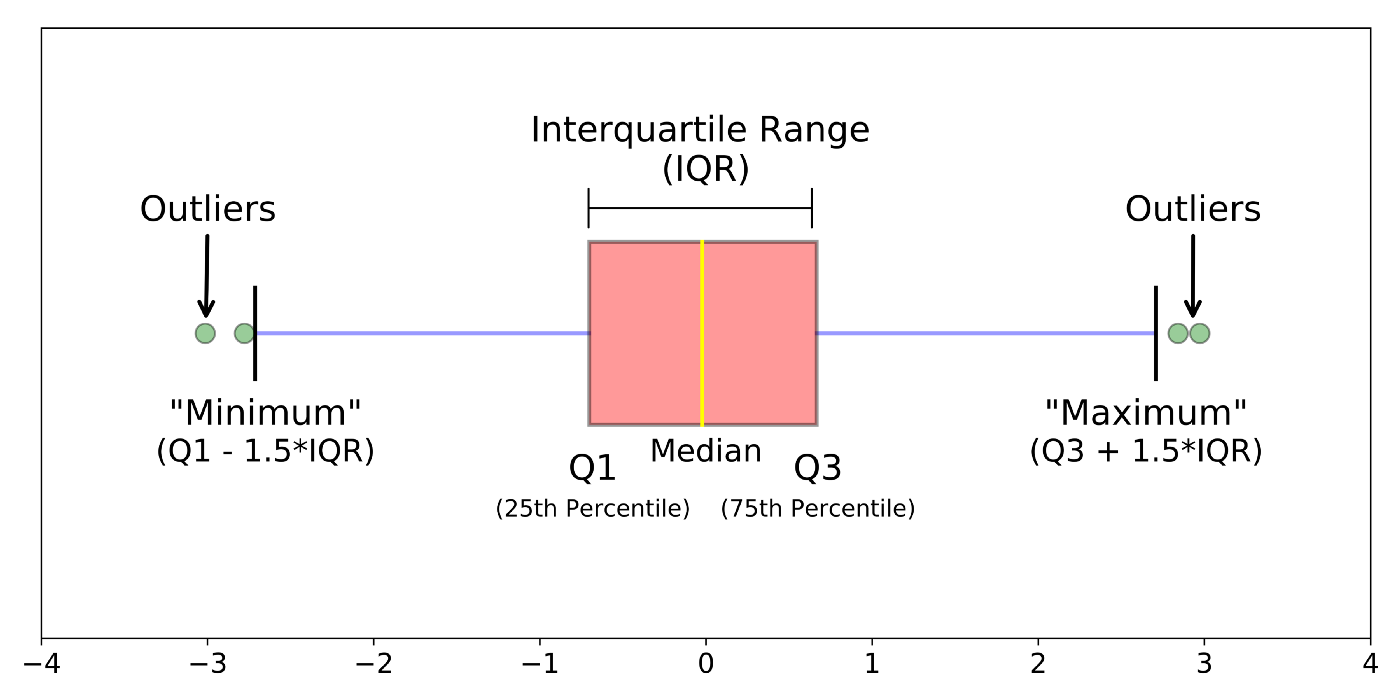

- `violinplot`: cumple las mismas funciones del `boxplot` pero además muestra una distribución de densidad de los datos.

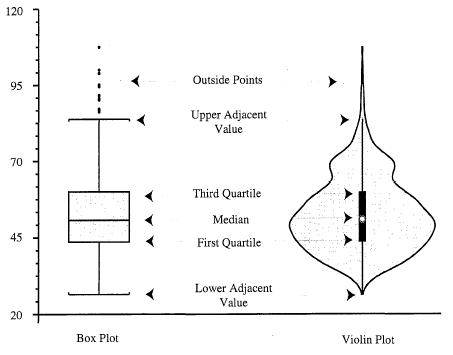

Primero, crearemos un boxplot para las muestras de peridotita:

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 10))

sns.boxplot(ax=axs[0], data=bas[["SiO2", "Al2O3", "FeOT", "CaO", "MgO"]], orient="h", flierprops={"marker":"o", "markersize": 4})
axs[0].grid()
axs[0].set_xlabel("%", fontsize=18)

sns.boxplot(ax=axs[1], data=bas[["Na2O", "K2O", "MnO", "TiO2"]], orient="h", flierprops={"marker":"o", "markersize": 4})
axs[1].grid()
axs[1].set_xlabel("%", fontsize=18)

fig.suptitle("Boxplot para las muestras de basalto", y=0.92, fontsize=25)
plt.show()

Los gráficos en `boxplot` nos ayudan a visualizar mejor la distribución de los datos, pero podemos mejorarlo usando `violinplot`:


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(18, 10))

sns.violinplot(ax=axs[0], data=bas[["SiO2", "Al2O3", "FeOT", "CaO", "MgO"]], orient="h")
axs[0].grid()
axs[0].set_xlabel("%", fontsize=18)

sns.violinplot(ax=axs[1], data=bas[["Na2O", "K2O", "MnO", "TiO2"]], orient="h")
axs[1].grid()
axs[1].set_xlabel("%", fontsize=18)

fig.suptitle("Violinplot para las muestras de basalto", y=0.92, fontsize=25)
plt.show()

***
<span style="color:gold">**Visualizando la matriz de correlación con `heatmap`**</span>

Ahora, crearemos una matriz de correlación para las muestras de basalto usando el método `corr`:

In [ ]:
bas.corr()

Esta matriz nos muestra la correlación de Spearman por cada par de columnas en el cuadro. <br>
Usaremos esta matriz para crear una visualización agradable de las diferentes correlaciones en el cuadro.

In [ ]:
# Matriz de correlación y columnas
corr = bas.corr(method="spearman")
columns = list(bas.columns)

# Generamos una matriz triangular
mask = np.triu(np.ones_like(corr, dtype=bool))

# Figura
fig, ax = plt.subplots(figsize=(7, 7))

# Mapa de colores para el gráfico
cmap = sns.color_palette("coolwarm", as_cmap=True)

# Mapa de calor
hm = sns.heatmap(corr, mask=mask, cmap=cmap, alpha=0.8,
                 vmin=-1, vmax=1, center=0,
                 fmt=".2f", square=True, linewidths=0.5, 
                 cbar_kws={"shrink": .8, "label": "Spearman"},
                 annot=True, annot_kws={"fontsize": 12, "color": "k"})

ax.tick_params(left=False, bottom=False)

# Detalles del eje X
xticks = ax.get_xticks()
new_xticks = [i for i in xticks[:-1]]
ax.set_xticks(new_xticks)
ax.set_xticklabels(columns[:-1])
ax.set_xlim(min(new_xticks)-0.5, max(new_xticks)+0.5)

# Detalles del eje Y
yticks = ax.get_yticks()
new_yticks = [i for i in yticks[1:]]
ax.set_yticks(new_yticks)
ax.set_yticklabels(columns[1:])
ax.set_ylim(max(new_yticks)+0.5, min(new_yticks)-0.5)

# TExto
for text in hm.texts:
     if text.get_text() == "0.00":
        text.set_text("")

ax.set_title("Matriz de correlación de Spearman", fontsize=16, x=0.55)

plt.show()

Vamos a filtrar aquellas correlaciones mayores a 0.5 y menores a -0.5:

In [ ]:
# Matriz de correlación y columnas
corr = bas.corr(method="spearman")
columns = list(bas.columns)

# Filtrando aquellos pares con una correlación alta
corr = corr.where((corr > 0.5) | (corr < -0.5), 0)

# Generamos una matriz triangular
mask = np.triu(np.ones_like(corr, dtype=bool))

# Figura
fig, ax = plt.subplots(figsize=(7, 7))

# Mapa de colores para el gráfico
cmap = sns.color_palette("coolwarm", as_cmap=True)

# Mapa de calor
hm = sns.heatmap(corr, mask=mask, cmap=cmap, alpha=0.8,
                 vmin=-1, vmax=1, center=0,
                 fmt=".2f", square=True, linewidths=0.5, 
                 cbar_kws={"shrink": .8, "label": "Spearman"},
                 annot=True, annot_kws={"fontsize": 12, "color": "k"})

ax.tick_params(left=False, bottom=False)

# Detalles del eje X
xticks = ax.get_xticks()
new_xticks = [i for i in xticks[:-1]]
ax.set_xticks(new_xticks)
ax.set_xticklabels(columns[:-1])
ax.set_xlim(min(new_xticks)-0.5, max(new_xticks)+0.5)

# Detalles del eje Y
yticks = ax.get_yticks()
new_yticks = [i for i in yticks[1:]]
ax.set_yticks(new_yticks)
ax.set_yticklabels(columns[1:])
ax.set_ylim(max(new_yticks)+0.5, min(new_yticks)-0.5)

# TExto
for text in hm.texts:
     if text.get_text() == "0.00":
        text.set_text("")

ax.set_title(r"""Matriz de correlación de Spearman
filtrado para $\rho > 0.7$ y $\rho < -0.7$""", fontsize=16, x=0.55)

plt.show()

Ahora, crearemos diagramas de dispersión para visualizar estos 3 pares.

***
<span style="color:gold">**Diagrama de dispersión con `scatterplot`**</span>

Colocaremos estos pares en una lista de tuplas llamada `pares`:

In [ ]:
pares = [("FeOT", "Al2O3"), ("FeOT", "MnO"), ("FeOT", "TiO2")]

Y lo usaremos dentro de la función `scatterplot` para crear una figura con 3 diagramas de dispersión:

In [ ]:
# Diagrama de dispersión para las muestras de peridotita
fig, axs = plt.subplots(1, 3, figsize=(16, 6))

for par, ax in zip(pares, axs):
    sns.scatterplot(ax=ax, data=ads, x=par[0], y=par[1], edgecolor="black", marker="o", s=12)
    ax.grid()
    
fig.suptitle("Diagramas de dispersión para pares de elementos con alta correlación (Basalto)", fontsize=20)

plt.tight_layout()

Por último, agregaremos los valores de estos pares con las muestras de andesita, dacita y riolita.

In [ ]:
# Diagrama de dispersión con todas las muestras
fig, axs = plt.subplots(1, 3, figsize=(16, 6))

for par, ax in zip(pares, axs):
    sns.scatterplot(ax=ax, data=rocas, x=par[0], y=par[1], marker="o", s=12, edgecolor="black", 
                    hue="Nombre", legend=True, alpha=0.8,
                    palette={"basalt":"blue", "andesite":"green", "dacite":"orange", "rhyolite":"red"}
                   )
    ax.grid(lw=1)
    ax.set_axisbelow(True)

fig.suptitle("Diagramas de dispersión para pares de elementos con alta correlación", fontsize=20)    

plt.tight_layout()

***
<span style="color:gold">**Histograma y Distribuciones de probabilidad con `histplot` y `kdeplot`**</span>

Podemos observar la distribución univariable de datos geoquímicos usando un **histograma** o una **distribución de probabilidad**.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(ax=axs[0], data=rocas, x="CaO", hue="Nombre", bins=20,
             alpha=0.5, edgecolor="black", linewidth=.5, 
             palette={"basalt":"blue", "andesite":"green", "dacite":"orange", "rhyolite":"red"})
axs[0].set_title("Histograma", fontsize=20)

sns.kdeplot(ax=axs[1], data=rocas, x="CaO", hue="Nombre", fill=True,
            cut=0, palette={"basalt":"blue", "andesite":"green", "dacite":"orange", "rhyolite":"red"})
axs[1].set_title("Distribución de probabilidad", fontsize=20)

plt.tight_layout()

También es posible observar la distribución bivariable:

> Nota: este gráfico puede tomar unos segundos en procesar.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(ax=axs[0], data=rocas, x="SiO2", y="FeOT", hue="Nombre", alpha=0.8, 
             palette={"basalt":"blue", "andesite":"green", "dacite":"orange", "rhyolite":"red"})
axs[0].set_title("Histograma", fontsize=20)
axs[0].grid()

sns.kdeplot(ax=axs[1], data=rocas, x="SiO2", y="FeOT", hue="Nombre", fill=True, cut=0, 
            palette={"basalt":"blue", "andesite":"green", "dacite":"orange", "rhyolite":"red"})
axs[1].set_title("Distribución de probabilidad", fontsize=20)
axs[1].grid()

plt.tight_layout()

***

<a id="parte-3"></a>

### <span style="color:lightgreen">**Pyrolite**</span>
***
**Pyrolite es una librería que te permite crear diagramas ternarios a partir de información geoquímica.**

Podemos verificar que tenemos `pyrolite` instalado usando el siguiente comando:

In [ ]:
!pip show pyrolite

Ahora, importaremos la función `pyroplot` del módulo `plot`:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(context="notebook", style="ticks")
from pyrolite.plot import pyroplot

In [ ]:
rocas = pd.read_csv("files/rocas.csv")
bas = rocas[rocas["Nombre"] == "basalt"].drop(columns=["Nombre"]).copy()
ads = rocas[rocas["Nombre"] == "andesite"].drop(columns=["Nombre"]).copy()
dac = rocas[rocas["Nombre"] == "dacite"].drop(columns=["Nombre"]).copy()
rhy = rocas[rocas["Nombre"] == "rhyolite"].drop(columns=["Nombre"]).copy()

Y crearemos un diagrama ternario, para esto tenemos que usar el método `pyroplot` en el cuadro que contenga la información geoquímica:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax1 = bas[["SiO2", "Al2O3", "FeOT"]].pyroplot.scatter(ax=ax, c="green", s=5, marker="o")

ax1.grid(axis="r", linestyle="--", linewidth=1)

plt.suptitle("Diagrama ternario - Basalto\n$SiO_{2} - Al_{2}O_{3} - FeOT$", fontsize=15, y=1.03)
plt.show()

Podemos establecer límites en el diagrama ternario usando el método `set_ternary_lim`. <br>
Además, podemos cambiar la etiqueta de cada esquina usando `set_tlabel`, `set_llabel` y `set_rlabel`:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax1 = bas[["SiO2", "Al2O3", "FeOT"]].pyroplot.scatter(ax=ax, c="green", s=5, marker="o")

ax1.set_ternary_lim(tmin=0.4, tmax=1.0,
                    lmin=0.0, lmax=0.6, 
                    rmin=0.0, rmax=0.6)

ax1.set_tlabel("$SiO_{2}$")
ax1.set_llabel("$Al_{2}O_{3}$")
ax1.set_rlabel("$FeOT$")

ax1.grid()

plt.suptitle("Diagrama ternario - Basalto\n$SiO_{2} - Al_{2}O_{3} - FeOT$", fontsize=15, y=1.03)
plt.show()

También podemos graficar distribuciones de probabilidad usando el método `density`:

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

bas[["Na2O", "CaO", "K2O"]].pyroplot.density(ax=axs[0])

bas[["Na2O", "CaO", "K2O"]].pyroplot.density(ax=axs[1], contours=[0.95, 0.66, 0.33],
                                             linewidths=[1, 2, 3], linestyles=["-.", "--", "-"],
                                             colors=["purple", "green", "blue"])

plt.suptitle("Diagrama ternario - Basalto\n$Na_{2}O - Ca_{2}O - K_{2}O$", fontsize=18, y=1.02)
plt.tight_layout()

Ahora, crearemos una figura que muestre la relación `SiO2 - Al2O3 - CaO` para todas las muestras:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax1 = bas[["SiO2", "Al2O3", "CaO"]].pyroplot.scatter(c="blue", s=2, marker="o", ax=ax, alpha=0.6, label="Basalto")

ads[["SiO2", "Al2O3", "CaO"]].pyroplot.scatter(c="green", s=2, marker="o", ax=ax, alpha=0.6, label="Andesita")

dac[["SiO2", "Al2O3", "CaO"]].pyroplot.scatter(c="orange", s=2, marker="o", ax=ax, alpha=0.6, label="Dacita")

rhy[["SiO2", "Al2O3", "CaO"]].pyroplot.scatter(c="red", s=2, marker="o", ax=ax, alpha=0.6, label="Riolita")

plt.suptitle("$SiO_{2} - Al_{2}O_{3} - CaO$", fontsize=20)
plt.legend(prop={"size": 12}, markerscale=4, frameon=True, loc=0)
ax1.grid()
plt.tight_layout()

Por último, crearemos otra figura que muestre la relación `SiO2 - Al2O3 - (FeOT + MgO)` para todas las muestras. <br>
Para esto, crearemos una columna llamada `FeOT + MgO` en ambos cuadros:

In [ ]:
bas["FeOT + MgO"] = bas["FeOT"] + bas["MgO"]
ads["FeOT + MgO"] = ads["FeOT"] + ads["MgO"]
dac["FeOT + MgO"] = dac["FeOT"] + dac["MgO"]
rhy["FeOT + MgO"] = rhy["FeOT"] + rhy["MgO"]

Ahora, podemos usar esta nueva columna en la figura:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax1 = bas[["SiO2", "Al2O3", "FeOT + MgO"]].pyroplot.scatter(c="blue", s=5, marker="o", ax=ax, alpha=0.6, label="Basalto")

ads[["SiO2", "Al2O3", "FeOT + MgO"]].pyroplot.scatter(c="green", s=5, marker="o", ax=ax, alpha=0.6, label="Andesita")

dac[["SiO2", "Al2O3", "FeOT + MgO"]].pyroplot.scatter(c="orange", s=5, marker="o", ax=ax, alpha=0.6, label="Dacita")

rhy[["SiO2", "Al2O3", "FeOT + MgO"]].pyroplot.scatter(c="red", s=5, marker="o", ax=ax, alpha=0.6, label="Riolita")

ax1.set_ternary_lim(0.4, 1.0,
                    0.0, 0.6,
                    0.0, 0.6)

plt.suptitle("$SiO_{2} - Al_{2}O_{3} - (FeOT + MgO)$", fontsize=20)
plt.legend(prop={'size': 12}, markerscale=4, frameon=True, loc=0)
ax1.grid()
plt.tight_layout()

***

<a id="parte-4"></a>

### <span style="color:lightgreen">**Mplstereonet**
***

**Esta librería permite crear figuras estereográficas equiangulares (red de Wulff) y equiareales (red de Schmidtt).**

Empezaremos revisando si `mplstereonet` se encuentra instalado:

> Si no se encuentra instalado, usar `!pip install mplstereonet`

In [ ]:
!pip show mplstereonet

Ahora, importaremos `mplstereonet` y cargaremos el archivo `data_estructural.csv`:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplstereonet

In [ ]:
datos = pd.read_csv("files/data_estructural.csv")
datos.head()

***
<span style="color:gold">**Diagrama de círculos máximos o Diagrama Beta** </span>

Este diagrama es utilizado para la representación de elementos planos. <br>
En la siguiente figura, usaremos la función `plane` para representar el plano. Esta función debe tener una dirección o rumbo (`strike`) y un buzamiento (`dip`). <br>
También es posible agregar el cabeceo de una línea o (también llamado `rake`) a partir de una dirección, buzamiento y ángulo de cabeceo (`rake_angle`).

Asignaremos las columnas de dirección y buzamiento a dos variables llamadas `strike` y `dip`:

In [ ]:
strike = datos.direccion
dip = datos.buzamiento
rake = datos.cabeceo

Para crear la figura estereográfica usaremos el método `add_subplot` y la opción `projection="stereonet"`.

> Nota: usaremos `constrained_layout=True` para mantener las etiquetas de los ángulos en posición correcta.

In [ ]:
fig = plt.figure(figsize=(5, 5), constrained_layout=True)
ax = fig.add_subplot(111, projection="equal_angle_stereonet")

ax.plane(strike, dip, c="black", linewidth=0.5)
ax.grid()

plt.show()

***
<span style="color:gold">**Diagrama de polos o Diagrama Pi** </span>
    
Usado cuando las medidas a representar en el diagrama son muy numerosas. <br>
En la siguiente figura, usaremos la función `pole` para representar el polo. Esta función debe tener una dirección (`strike`) y buzamiento (`dip`).

In [ ]:
fig = plt.figure(figsize=(5, 5), constrained_layout=True)
ax = fig.add_subplot(111, projection="equal_angle_stereonet")

ax.pole(strike, dip, c="red", markersize=5)
ax.grid()

plt.show()

***
<span style="color:gold">**Diagrama de densidad de polos** </span>

Usando la red de Schmidt (equiareal), podemos hacer un recuento directo de los polos y calcular su valor estadístico por unidad de superficie, determinando las direcciones y buzamiento predominantes.

In [ ]:
fig = plt.figure(figsize=(5, 5), constrained_layout=True)
ax = fig.add_subplot(111, projection="equal_area_stereonet")

cax = ax.density_contourf(strike, dip, measurement="poles", cmap="gist_earth", sigma=1.5)
ax.density_contour(strike, dip, measurement="poles", colors="black", sigma=1.5)
   
ax.pole(strike, dip, c="red", ms=5)
ax.grid(linewidth=0.5)
# fig.colorbar(cax, orientation="horizontal")

plt.show()

***
<span style="color:gold">**Stereonet interactiva** </span>

Usando una herramienta de visualización interactiva, crearemos una red estereográfica en donde podemos alterar los valores de rumbo, buzamiento y cabeceo de un plano.

In [ ]:
import ipywidgets as widgets

In [ ]:
def stereonet(rotation, strike, dip, rake):
    fig = plt.figure(figsize=(6, 6), constrained_layout=True)
    
    ax = fig.add_subplot(111, projection="equal_angle_stereonet", rotation=rotation)
    
    ax.plane(strike, dip, color="green", linewidth=2)
    ax.pole(strike, dip, color="red", ms=10)
    ax.rake(strike, dip, rake, color="blue", ms=10)

    ax.grid()
    
    plt.show()
    
widgets.interact(stereonet,
                 rotation=widgets.IntSlider(min=0, max=360, step=5, value=0, description="Rotación"),
                 strike=widgets.IntSlider(min=0, max=360, step=5, value=90, description="Rumbo"),
                 dip=widgets.IntSlider(min=0, max=90, step=1, value=45, description="Buzamiento"),
                 rake=widgets.IntSlider(min=-90, max=90, step=1, value=45, description="Cabeceo"));

***